In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design()  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## accuracy-vs-parameters

**Figure 1: ImageNet top-1 accuracy versus number of parameters for EfficientNets and other ConvNets.** The red line connects EfficientNet-B0 to B7; the dotted and dashed grey lines connect hand-designed and NAS baselines, which the original figure joins. EfficientNet-B7 reaches 84.4% top-1 accuracy with 66M parameters, above AmoebaNet-C (83.5%) with 2.3× fewer parameters.

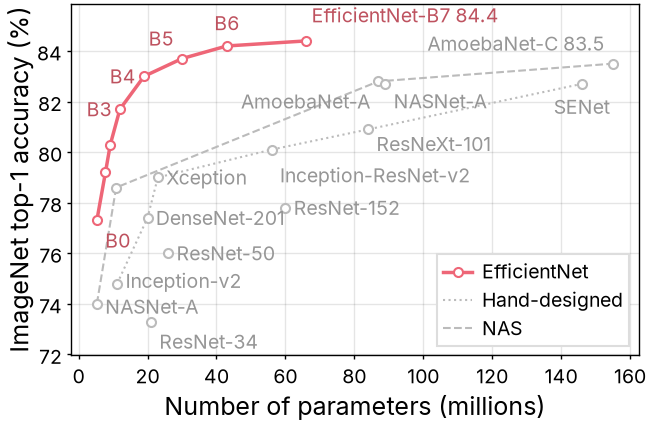

In [2]:
with open("../accuracy-vs-parameters.json") as f:
    models = json.load(f)

efficientnet = [m for m in models if m["family"] == "EfficientNet"]
hand_designed = [m for m in models if m["family"] == "hand-designed (dotted gray front)"]
nas = [m for m in models if m["family"] == "NAS (dashed blue front)"]
baselines = [m for m in models if m["family"] != "EfficientNet"]

labels = {"EfficientNet-B7": "EfficientNet-B7 84.4", "AmoebaNet-C": "AmoebaNet-C 83.5"}
# label position per point (offset in points, alignment), chosen so no two labels overlap
placements = {
    "EfficientNet-B0": (3, -3, "left", "top"),
    "EfficientNet-B3": (-3, 0, "right", "center"),
    "EfficientNet-B4": (-3, 0, "right", "center"),
    "EfficientNet-B5": (-3, 3, "right", "bottom"),
    "EfficientNet-B6": (0, 4, "center", "bottom"),
    "EfficientNet-B7": (2, 5, "left", "bottom"),
    "AmoebaNet-C": (-3, 3, "right", "bottom"),
    "SENet": (0, -4, "center", "top"),
    "AmoebaNet-A": (-3, -3, "right", "top"),
    "NASNet-A (large)": (3, -2, "left", "top"),
    "ResNeXt-101": (3, -1, "left", "top"),
    "Inception-ResNet-v2": (3, -5, "left", "top"),
    "ResNet-152": (3, 0, "left", "center"),
    "Xception": (3, 0, "left", "center"),
    "DenseNet-201": (3, 0, "left", "center"),
    "ResNet-50": (3, 0, "left", "center"),
    "Inception-v2": (3, 1, "left", "center"),
    "NASNet-A (mobile)": (3, -1, "left", "center"),
    "ResNet-34": (3, -3, "left", "top"),
}

fig, ax = plt.subplots(figsize=(3.25, 2))
ax.plot([m["params_millions"] for m in hand_designed], [m["top1_accuracy"] for m in hand_designed],
        linestyle=":", linewidth=paper.dashed_width, color=colors["neutral"], zorder=1, label="Hand-designed")
ax.plot([m["params_millions"] for m in nas], [m["top1_accuracy"] for m in nas],
        linestyle="--", linewidth=paper.dashed_width, color=colors["neutral"], zorder=1, label="NAS")
ax.plot([m["params_millions"] for m in baselines], [m["top1_accuracy"] for m in baselines],
        "o", color=colors["neutral"])
ax.plot([m["params_millions"] for m in efficientnet], [m["top1_accuracy"] for m in efficientnet],
        "o-", color=colors["ours"], label="EfficientNet")

for m in models:
    if m["label_in_figure"] is None:
        continue
    color = colors["ours"] if m["family"] == "EfficientNet" else colors["neutral"]
    dx, dy, ha, va = placements[m["model"]]
    ax.annotate(labels.get(m["model"], m["label_in_figure"]), (m["params_millions"], m["top1_accuracy"]),
                xytext=(dx, dy), textcoords="offset points", ha=ha, va=va, fontsize=7, color=darken(color))

ax.set_xlabel("Number of parameters (millions)")
ax.set_ylabel("ImageNet top-1 accuracy (%)")
handles, names = ax.get_legend_handles_labels()
ax.legend([handles[2], handles[0], handles[1]], [names[2], names[0], names[1]], loc="lower right")

fit_height(fig, ax, aspect=0.618)
fig.savefig("accuracy-vs-parameters.pdf")
fig.savefig("accuracy-vs-parameters.png")
plt.show()